# Hotel Search Ranking, Part 3: The Ranking Model

Part 2 set the bar. On the fair test, the searches shown in random order, the best simple rule was "best location first" at 0.234 NDCG@5. Now I train a proper ranking model and see how far it gets past that.

The model is **LightGBM with the LambdaRank objective**. In plain words: instead of predicting "will this hotel be booked, yes or no" for each hotel on its own, it learns to put hotels **in the right order within each search**, and it cares most about getting the top of the list right. That's exactly what a guest experiences.

I also test one question that came out of Part 1: since clicks in Expedia's own order are inflated by position, is the model better off learning **only from the random searches**, even though there are far fewer of them?

Author: Siddharth Suman

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import warnings

# Newer LightGBM versions print a harmless notice about argument names
warnings.filterwarnings('ignore', message='.*eval_set.*')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/expedia-hotel-ranking'
except ImportError:
    WORK_DIR = 'data'

os.makedirs('images', exist_ok=True)
data = pd.read_parquet(os.path.join(WORK_DIR, 'features.parquet'))
baselines = pd.read_csv(os.path.join(WORK_DIR, 'baseline_results.csv'), index_col=0)

FEATURES = ['log_price', 'price_rank', 'price_vs_search_avg', 'price_vs_usual',
            'prop_starrating', 'star_rank', 'prop_review_score', 'review_rank',
            'prop_location_score1', 'location1_rank', 'location2_filled', 'location2_rank',
            'prop_brand_bool', 'promotion_flag',
            'hotel_booking_rate', 'hotel_click_rate_random', 'hotel_seen_before',
            'visitor_known', 'star_gap_to_visitor', 'price_gap_to_visitor',
            'srch_length_of_stay', 'srch_booking_window', 'srch_adults_count',
            'srch_children_count', 'srch_room_count', 'srch_saturday_night_bool',
            'hotels_in_search']

print(data['period'].value_counts())
print("lightgbm version:", lgb.__version__)

Mounted at /content/drive
period
train    985692
test     488376
Name: count, dtype: int64
lightgbm version: 4.6.0


## Train, validation and test

The test period (the newest 20% of searches) stays untouched until the very end. From the training period I hold back 15% of searches as a **validation set**. The model checks itself against it while learning and stops once it stops improving, which keeps it from memorising the training searches.

In [2]:
train_all = data[data['period'] == 'train']
test = data[data['period'] == 'test'].copy()

rng = np.random.default_rng(7)
train_ids = train_all['srch_id'].unique()
valid_ids = set(rng.choice(train_ids, size=int(len(train_ids) * 0.15), replace=False))
is_valid = train_all['srch_id'].isin(valid_ids)
fit_part, valid_part = train_all[~is_valid], train_all[is_valid]

print(f"Fit:        {fit_part['srch_id'].nunique():,} searches")
print(f"Validation: {valid_part['srch_id'].nunique():,} searches")
print(f"Test:       {test['srch_id'].nunique():,} searches")

Fit:        33,938 searches
Validation: 5,989 searches
Test:       19,964 searches


## Training

LightGBM needs to know which rows belong to the same search, so I pass it the number of hotels in each search (the "group"). The rows are already sorted by search.

The relevance labels are 0, 1 and 5. LightGBM's default way of turning labels into importance is 2 to the power of the label, minus 1, so a booking counts 31 and a click counts 1. That's the same scoring I used for the baselines, so the comparison is fair.

In [3]:
def groups(frame):
    return frame.groupby('srch_id', sort=False).size().to_numpy()

def train_ranker(fit_frame, valid_frame, label):
    model = lgb.LGBMRanker(
        objective='lambdarank',
        n_estimators=1500,
        learning_rate=0.05,
        num_leaves=63,
        min_child_samples=100,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=42,
        verbose=-1,
    )
    model.fit(
        fit_frame[FEATURES], fit_frame['relevance'], group=groups(fit_frame),
        eval_set=[(valid_frame[FEATURES], valid_frame['relevance'])],
        eval_group=[groups(valid_frame)],
        eval_at=[5, 38],
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)],
    )
    print(f"{label}: stopped at {model.best_iteration_} trees, "
          f"validation NDCG@5 {model.best_score_['valid_0']['ndcg@5']:.3f}")
    return model

# Model A learns from every training search
model_all = train_ranker(fit_part, valid_part, 'Model A, all searches')

# Model B learns only from searches shown in random order, where position didn't steer the clicks
fit_rnd = fit_part[fit_part['random_bool'] == 1]
valid_rnd = valid_part[valid_part['random_bool'] == 1]
model_rnd = train_ranker(fit_rnd, valid_rnd, 'Model B, random searches only')

[200]	valid_0's ndcg@5: 0.372287	valid_0's ndcg@38: 0.500846
Model A, all searches: stopped at 187 trees, validation NDCG@5 0.374
Model B, random searches only: stopped at 26 trees, validation NDCG@5 0.328


## Scoring on the test period

I use exactly the same NDCG function as in Part 2, so the model and the baselines are measured the same way.

In [4]:
def ndcg(frame, score_col, k, seed=0):
    d = frame[['srch_id', 'relevance', score_col]].copy()
    d['tiebreak'] = np.random.default_rng(seed).random(len(d))
    d = d.sort_values(['srch_id', score_col, 'tiebreak'], ascending=[True, False, True])
    rank = d.groupby('srch_id').cumcount() + 1
    dcg = np.where(rank <= k, (2.0 ** d['relevance'] - 1) / np.log2(rank + 1), 0)
    dcg = pd.Series(dcg, index=d.index).groupby(d['srch_id']).sum()

    ideal = d.sort_values(['srch_id', 'relevance'], ascending=[True, False])
    irank = ideal.groupby('srch_id').cumcount() + 1
    idcg = np.where(irank <= k, (2.0 ** ideal['relevance'] - 1) / np.log2(irank + 1), 0)
    idcg = pd.Series(idcg, index=ideal.index).groupby(ideal['srch_id']).sum()

    scored = idcg > 0
    return (dcg[scored] / idcg[scored]).mean()

test['model_all'] = model_all.predict(test[FEATURES])
test['model_rnd'] = model_rnd.predict(test[FEATURES])

subsets = {'Random searches': test[test['random_bool'] == 1],
           'Expedia ordered searches': test[test['random_bool'] == 0]}

rows = []
for name, col in [('Model A, all searches', 'model_all'), ('Model B, random searches only', 'model_rnd')]:
    row = {'Ranking': name}
    for sname, sdf in subsets.items():
        row[f'{sname} @5'] = ndcg(sdf, col, 5)
        row[f'{sname} @38'] = ndcg(sdf, col, 38)
    rows.append(row)
model_results = pd.DataFrame(rows).set_index('Ranking')

compare = pd.concat([
    model_results[['Random searches @5', 'Expedia ordered searches @5']],
    baselines.loc[['Best location first', 'Most booked before', 'Cheapest first', 'Random'],
                  ['Random searches @5', 'Expedia ordered searches @5']],
])
print(model_results.round(3))
print()
print(compare.round(3))

simple_rules = baselines.drop(index=["Expedia's own order", 'Random'])
best_rule = simple_rules['Random searches @5'].idxmax()
best_simple = simple_rules.loc[best_rule, 'Random searches @5']
print()
for name in model_results.index:
    lift = model_results.loc[name, 'Random searches @5'] / best_simple - 1
    print(f"{name}: {lift:+.0%} against the best simple rule ({best_rule}), on random searches")

                               Random searches @5  Random searches @38  \
Ranking                                                                  
Model A, all searches                       0.316                0.463   
Model B, random searches only               0.293                0.448   

                               Expedia ordered searches @5  \
Ranking                                                      
Model A, all searches                                0.377   
Model B, random searches only                        0.335   

                               Expedia ordered searches @38  
Ranking                                                      
Model A, all searches                                 0.503  
Model B, random searches only                         0.471  

                               Random searches @5  Expedia ordered searches @5
Model A, all searches                       0.316                        0.377
Model B, random searches only               0.2

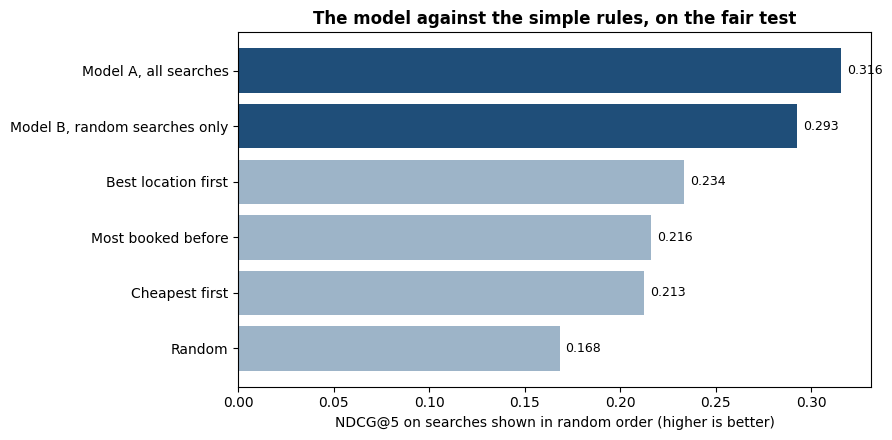

In [5]:
plot = compare['Random searches @5'].sort_values()
colors = ['#1F4E79' if 'Model' in i else '#9DB4C8' for i in plot.index]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot.index, plot.values, color=colors)
for i, v in enumerate(plot.values):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlabel('NDCG@5 on searches shown in random order (higher is better)')
ax.set_title('The model against the simple rules, on the fair test', fontweight='bold')
plt.tight_layout()
plt.savefig('images/03_model_vs_baselines.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells me

The fair comparison is the random searches, where nobody gets help from position. That's where the model has to beat "best location first", and the gap between them is the value of combining many signals instead of relying on one.

Expedia's own order still scores higher in the searches Expedia ordered itself, but as Part 2 showed, that number is inflated: those searches were partly marked by the order Expedia chose. My model never sees position, so it can't benefit from that.

Model A against Model B answers the question from Part 1. Model A has about three times as much data, but much of it is shaped by position. Model B has cleaner data, but far less of it. Whichever wins on the random test searches tells me which matters more here: the amount of data, or how clean it is.

## What the model relies on

LightGBM can report how much each feature helped it make better splits ("gain"). It's a rough guide, not proof of cause and effect, and Part 4 will dig deeper with SHAP values. But it already shows what the model leans on.

Feature importance for Model A (share of total gain):
location2_rank             14.5%
price_vs_usual             11.8%
location2_filled            8.7%
star_rank                   8.3%
hotel_booking_rate          8.0%
price_rank                  7.8%
prop_location_score1        5.9%
review_rank                 4.8%
price_vs_search_avg         4.6%
hotel_click_rate_random     3.7%
log_price                   3.6%
location1_rank              3.6%
srch_booking_window         2.4%
hotels_in_search            2.3%
promotion_flag              2.2%
dtype: object


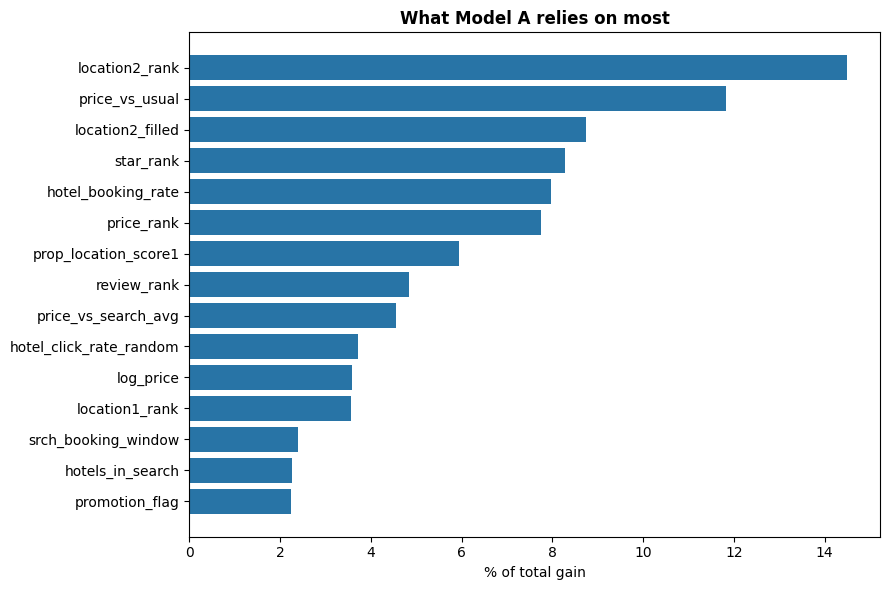

In [6]:
best = model_all if model_results.loc['Model A, all searches', 'Random searches @5'] >= \
                   model_results.loc['Model B, random searches only', 'Random searches @5'] else model_rnd
best_name = 'Model A' if best is model_all else 'Model B'

importance = (pd.Series(best.booster_.feature_importance(importance_type='gain'), index=FEATURES)
                .sort_values(ascending=False))
importance = importance / importance.sum()
print(f"Feature importance for {best_name} (share of total gain):")
print(importance.head(15).map('{:.1%}'.format))

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top.values * 100, color='#2874A6')
ax.set_xlabel('% of total gain')
ax.set_title(f'What {best_name} relies on most', fontweight='bold')
plt.tight_layout()
plt.savefig('images/03_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

### What this tells me

The ranking of features is the model's version of what a guest weighs up when scanning a list of hotels. I expect location and price relative to the other hotels in the search near the top, because Part 2 already showed those are the strongest single signals. Hotel popularity from past bookings should matter too.

What I watch for is the model leaning almost entirely on one thing, especially price. That would be the "cheap rooms get pushed to the top" risk I want to check properly in Part 4.

## Saving for Part 4

In [7]:
test['score'] = best.predict(test[FEATURES])
test['model_rank'] = test.groupby('srch_id')['score'].rank(ascending=False, method='first')
keep = ['srch_id', 'prop_id', 'random_bool', 'position', 'click_bool', 'booking_bool',
        'relevance', 'price_usd', 'score', 'model_rank'] + FEATURES
test[keep].to_parquet(os.path.join(WORK_DIR, 'test_predictions.parquet'), index=False)
best.booster_.save_model(os.path.join(WORK_DIR, 'ranker.txt'))
model_results.to_csv(os.path.join(WORK_DIR, 'model_results.csv'))
print(f"Saved {best_name} and its test predictions to Drive")

Saved Model A and its test predictions to Drive


## What I'm taking into Part 4

* Part 4 looks at the model through a hotelier's eyes: which features push a hotel up or down, and whether the model ranks hotels too highly when they collect clicks but few bookings.
* I'll also check whether cheap hotels end up higher in the model's ranking than guests' bookings justify, since that's the most common way a ranking can go wrong commercially.